In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score

# Machine Learning Algorithms
from sklearn.linear_model import LinearRegression, HuberRegressor, Ridge, LogisticRegression, BayesianRidge
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.kernel_ridge import KernelRidge
from sklearn.svm import SVC, SVR
from scipy.stats import norm



In [ ]:
# -------------------------------------------------------------------------
# 1. Load Data & Preprocessing Pipeline
# -------------------------------------------------------------------------
df = pd.read_csv('a.csv')

# Drop unique identifier case_id
df = df.drop(columns=['case_id'])

# Targets
y_regression = df['risk_score']
y_classification = df['bail_eligibility'].astype(int)

# Features (excluding target columns)
X = df.drop(columns=['risk_score', 'bail_eligibility'])

categorical_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ]
)

# Transform Features
X_processed = preprocessor.fit_transform(X)

# Train-Test Splits
X_train, X_test, y_reg_train, y_reg_test = train_test_split(
    X_processed, y_regression, test_size=0.2, random_state=42
)

_, _, y_cls_train, y_cls_test = train_test_split(
    X_processed, y_classification, test_size=0.2, random_state=42, stratify=y_classification
)


In [ ]:

# -------------------------------------------------------------------------
# 2. Regression Algorithms (Target: risk_score)
# -------------------------------------------------------------------------
print("=" * 60)
print("SECTION 1: LINEAR & KERNEL REGRESSION MODELS")
print("=" * 60)

reg_models = {
    "1. MLE - Least Squares (OLS)": LinearRegression(),
    "2. Robust Linear Regression (Huber)": HuberRegressor(max_iter=1000),
    "3. Ridge Regression ($L_2$ Regularization)": Ridge(alpha=1.0),
    "4. Bayesian Linear Regression": BayesianRidge(),
    "5. Kernel Ridge Regression (RBF Kernel Trick)": KernelRidge(kernel='rbf', gamma=0.1),
    "6. Support Vector Regression (SVR)": SVR(kernel='rbf', C=1.0)
}

reg_results = []
for name, model in reg_models.items():
    model.fit(X_train, y_reg_train)
    preds = model.predict(X_test)
    mse = mean_squared_error(y_reg_test, preds)
    r2 = r2_score(y_reg_test, preds)
    reg_results.append({"Algorithm": name, "MSE": round(mse, 4), "R2 Score": round(r2, 4)})

df_reg_results = pd.DataFrame(reg_results)
print(df_reg_results.to_string(index=False))



SECTION 1: LINEAR & KERNEL REGRESSION MODELS
                                    Algorithm    MSE  R2 Score
                 1. MLE - Least Squares (OLS) 0.0000    1.0000
          2. Robust Linear Regression (Huber) 0.0000    1.0000
   3. Ridge Regression ($L_2$ Regularization) 0.0000    1.0000
                4. Bayesian Linear Regression 0.0000    1.0000
5. Kernel Ridge Regression (RBF Kernel Trick) 0.0084    0.9857
           6. Support Vector Regression (SVR) 0.0068    0.9884


In [ ]:

# -------------------------------------------------------------------------
# 3. Bayesian Logistic Regression via Laplace Approximation
# -------------------------------------------------------------------------
class BayesianLogisticRegressionLaplace:
    """Bayesian Logistic Regression using Laplace Approximation."""
    def __init__(self, alpha=1.0):
        self.alpha = alpha  # Prior precision
        self.w_map = None
        self.cov_matrix = None

    def fit(self, X, y):
        # Add intercept column
        X = np.hstack([np.ones((X.shape[0], 1)), X])
        n_features = X.shape[1]

        # Fit MAP estimate using L2 Logistic Regression
        clf = LogisticRegression(C=1.0 / self.alpha, fit_intercept=False, solver='lbfgs', max_iter=1000)
        clf.fit(X, y)
        self.w_map = clf.coef_.ravel()

        # Compute Hessian for Laplace Approximation
        p = 1.0 / (1.0 + np.exp(-X @ self.w_map))
        V = p * (1.0 - p)
        Hessian = (X.T * V) @ X + self.alpha * np.eye(n_features)
        self.cov_matrix = np.linalg.inv(Hessian)

    def predict_proba(self, X):
        X = np.hstack([np.ones((X.shape[0], 1)), X])
        mu_a = X @ self.w_map
        var_a = np.sum(X @ self.cov_matrix * X, axis=1)
        # Probit approximation to marginal probability
        kappa = 1.0 / np.sqrt(1.0 + (np.pi * var_a / 8.0))
        prob = 1.0 / (1.0 + np.exp(-kappa * mu_a))
        return np.vstack([1 - prob, prob]).T

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


In [ ]:


# -------------------------------------------------------------------------
# 4. Classification Algorithms (Target: bail_eligibility)
# -------------------------------------------------------------------------
print("\n" + "=" * 60)
print("SECTION 2: CLASSIFICATION & DISCRIMINANT MODELS")
print("=" * 60)

cls_models = {
    "1. Discriminant Function: LDA": LinearDiscriminantAnalysis(),
    "2. Discriminant Function: QDA": QuadraticDiscriminantAnalysis(reg_param=0.1),
    "3. Probabilistic Generative: Gaussian Naive Bayes": GaussianNB(),
    "4. Probabilistic Discriminative: Logistic Regression": LogisticRegression(),
    "5. Laplacian Approx: Bayesian Logistic Regression": BayesianLogisticRegressionLaplace(alpha=1.0),
    "6. Linear Support Vector Machine (SVM)": SVC(kernel='linear', C=1.0),
    "7. Non-Linear Kernel SVM (RBF Kernel Trick)": SVC(kernel='rbf', C=1.0)
}

cls_results = []
for name, model in cls_models.items():
    model.fit(X_train, y_cls_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_cls_test, preds)
    f1 = f1_score(y_cls_test, preds)
    cls_results.append({"Algorithm": name, "Accuracy": round(acc, 4), "F1-Score": round(f1, 4)})

df_cls_results = pd.DataFrame(cls_results)
print(df_cls_results.to_string(index=False))




SECTION 2: CLASSIFICATION & DISCRIMINANT MODELS
                                           Algorithm  Accuracy  F1-Score
                       1. Discriminant Function: LDA     0.875       0.0
                       2. Discriminant Function: QDA     0.875       0.0
   3. Probabilistic Generative: Gaussian Naive Bayes     0.870       0.0
4. Probabilistic Discriminative: Logistic Regression     0.875       0.0
   5. Laplacian Approx: Bayesian Logistic Regression     0.875       0.0
              6. Linear Support Vector Machine (SVM)     0.875       0.0
         7. Non-Linear Kernel SVM (RBF Kernel Trick)     0.875       0.0


/tmp/ipykernel_1954/1656924130.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_reg_results, x="R2 Score", y="Algorithm", ax=axes[0], palette="crest")
/tmp/ipykernel_1954/1656924130.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_cls_results, x="Accuracy", y="Algorithm", ax=axes[1], palette="viridis")


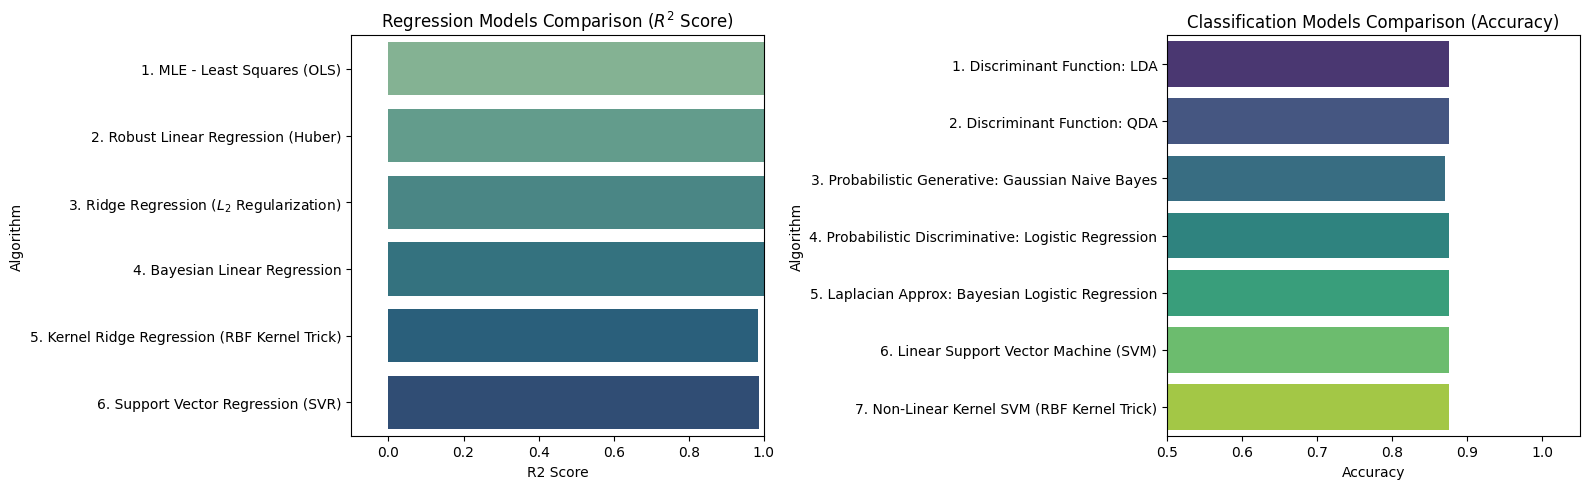

In [ ]:

# -------------------------------------------------------------------------
# 5. Visualization: Model Comparisons
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Regression Plot
sns.barplot(data=df_reg_results, x="R2 Score", y="Algorithm", ax=axes[0], palette="crest")
axes[0].set_title("Regression Models Comparison ($R^2$ Score)")
axes[0].set_xlim(-0.1, 1.0)

# Classification Plot
sns.barplot(data=df_cls_results, x="Accuracy", y="Algorithm", ax=axes[1], palette="viridis")
axes[1].set_title("Classification Models Comparison (Accuracy)")
axes[1].set_xlim(0.5, 1.05)

plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# UNIT 3: MIXTURE MODELS, EM, CLUSTERING & DIMENSIONALITY REDUCTION (PCA)
# Dataset: Legal Cases (`a.csv`)
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch


In [ ]:

# ------------------------------------------------------------------------------
# STEP 1: Feature Selection & Scaling for Unsupervised Learning
# ------------------------------------------------------------------------------
# Drop unique IDs and target labels
X_u3 = df.drop(columns=['case_id', 'bail_eligibility', 'penalty_severity'], errors='ignore')

# One-Hot Encoding for categorical features
X_u3_encoded = pd.get_dummies(X_u3, drop_first=True)
for col in X_u3_encoded.columns:
    if X_u3_encoded[col].dtype == 'bool':
        X_u3_encoded[col] = X_u3_encoded[col].astype(int)

# Standardize features
scaler = StandardScaler()
X_u3_scaled = scaler.fit_transform(X_u3_encoded)

print(f"Features ready for Unit 3 clustering. Shape: {X_u3_scaled.shape}")


Features ready for Unit 3 clustering. Shape: (1000, 20)


In [ ]:


# ------------------------------------------------------------------------------
# STEP 2: Dimensionality Reduction using PCA (Principal Component Analysis)
# ------------------------------------------------------------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_u3_scaled)

explained_var = pca.explained_variance_ratio_
print(f"\n--- PCA Summary ---")
print(f"Explained Variance Ratio (PC1 & PC2): {explained_var}")
print(f"Total Variance Explained by 2 Components: {sum(explained_var)*100:.2f}%")




--- PCA Summary ---
Explained Variance Ratio (PC1 & PC2): [0.09959742 0.0790221 ]
Total Variance Explained by 2 Components: 17.86%


In [ ]:

# ------------------------------------------------------------------------------
# STEP 3: Clustering Algorithms Implementation
# ------------------------------------------------------------------------------
n_clusters = 3  # Number of categories/clusters to form

# A. K-Means Clustering
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_u3_scaled)

# B. Mixture of Gaussians (GMM - Expectation Maximization)
gmm = GaussianMixture(n_components=n_clusters, random_state=42)
gmm_labels = gmm.fit_predict(X_u3_scaled)

# C. Hierarchical Clustering (Agglomerative)
hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
hc_labels = hc.fit_predict(X_u3_scaled)


In [ ]:


# ------------------------------------------------------------------------------
# STEP 4: Comparative Evaluation Metrics (Silhouette & Davies-Bouldin)
# ------------------------------------------------------------------------------
results_unit3 = pd.DataFrame({
    'Algorithm': ['K-Means Clustering', 'Gaussian Mixture Model (GMM)', 'Hierarchical Clustering'],
    'Silhouette Score (Higher is better)': [
        silhouette_score(X_u3_scaled, kmeans_labels),
        silhouette_score(X_u3_scaled, gmm_labels),
        silhouette_score(X_u3_scaled, hc_labels)
    ],
    'Davies-Bouldin Index (Lower is better)': [
        davies_bouldin_score(X_u3_scaled, kmeans_labels),
        davies_bouldin_score(X_u3_scaled, gmm_labels),
        davies_bouldin_score(X_u3_scaled, hc_labels)
    ]
})

print("\n=== UNIT 3: COMPARATIVE PERFORMANCE ANALYSIS ===")
print(results_unit3.to_string(index=False))




=== UNIT 3: COMPARATIVE PERFORMANCE ANALYSIS ===
                   Algorithm  Silhouette Score (Higher is better)  Davies-Bouldin Index (Lower is better)
          K-Means Clustering                             0.081806                                3.105041
Gaussian Mixture Model (GMM)                             0.062351                                3.846036
     Hierarchical Clustering                             0.083281                                3.366106


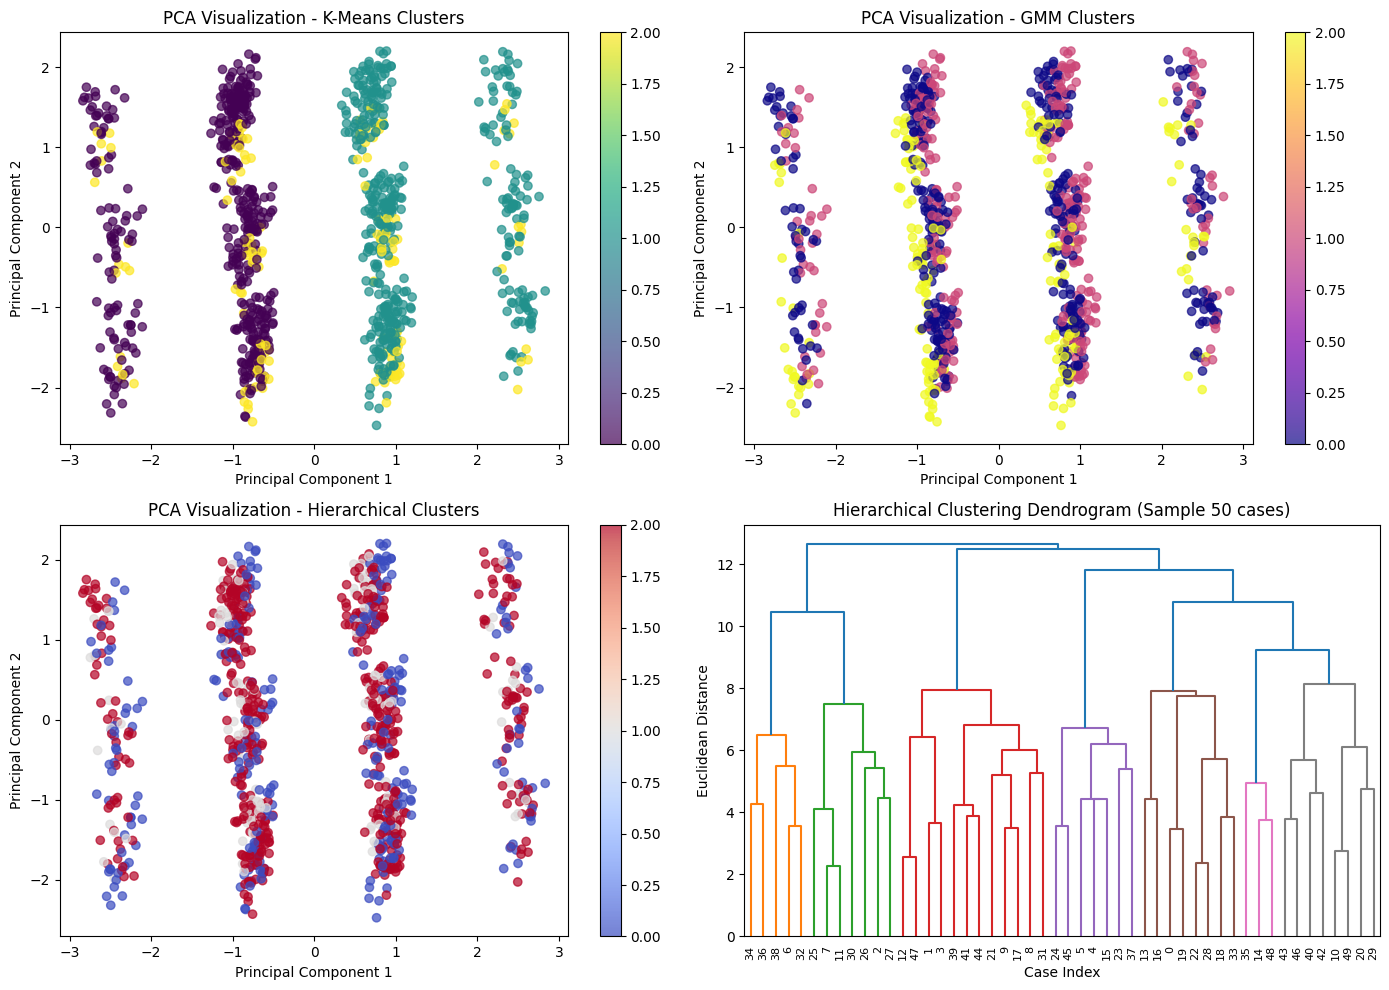

In [ ]:

# ------------------------------------------------------------------------------
# STEP 5: Visualizations
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. PCA Scatter Plot with K-Means Clusters
scatter0 = axes[0, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis', alpha=0.7)
axes[0, 0].set_title('PCA Visualization - K-Means Clusters')
axes[0, 0].set_xlabel('Principal Component 1')
axes[0, 0].set_ylabel('Principal Component 2')
fig.colorbar(scatter0, ax=axes[0, 0])

# 2. PCA Scatter Plot with GMM Clusters
scatter1 = axes[0, 1].scatter(X_pca[:, 0], X_pca[:, 1], c=gmm_labels, cmap='plasma', alpha=0.7)
axes[0, 1].set_title('PCA Visualization - GMM Clusters')
axes[0, 1].set_xlabel('Principal Component 1')
axes[0, 1].set_ylabel('Principal Component 2')
fig.colorbar(scatter1, ax=axes[0, 1])

# 3. PCA Scatter Plot with Hierarchical Clusters
scatter2 = axes[1, 0].scatter(X_pca[:, 0], X_pca[:, 1], c=hc_labels, cmap='coolwarm', alpha=0.7)
axes[1, 0].set_title('PCA Visualization - Hierarchical Clusters')
axes[1, 0].set_xlabel('Principal Component 1')
axes[1, 0].set_ylabel('Principal Component 2')
fig.colorbar(scatter2, ax=axes[1, 0])

# 4. Hierarchical Clustering Dendrogram
dendrogram = sch.dendrogram(sch.linkage(X_u3_scaled[:50], method='ward'), ax=axes[1, 1])
axes[1, 1].set_title('Hierarchical Clustering Dendrogram (Sample 50 cases)')
axes[1, 1].set_xlabel('Case Index')
axes[1, 1].set_ylabel('Euclidean Distance')

plt.tight_layout()
plt.show()